# Zarr Demonstration Notebook for C3S / CCI Soil Moisture users

This notebook uses the **TCDR combined product (v202605) stored as a single Zarr store** and focuses on what Zarr changes:
how the data is organised, how you access it, and why it is fast.

0. Setup
1. What is Zarr, compared with netCDF
2. The dataset as one Zarr store
3. How a remote Zarr store is organised
4. Reading metadata
5. Reading data: only the chunks you need
6. Analysing and plotting
7. Parallel writing and reading: Zarr vs netCDF
8. Choosing chunks
9. A netCDF ↔ Zarr cheat sheet

> The data is streamed from `data.eodc.eu`, so you need internet access.
> One full run downloads a few hundred MB.

## 0. Setup

Run this notebook with the project environment:

```bash
uv sync
uv run jupyter lab
```

Dask is set to use **8 threads**. Zarr reads, decompresses and writes independent chunks in parallel, so more cores help.

In [22]:
import json
import math
import shutil
import time
from pathlib import Path

import dask
import fsspec
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import zarr

N_WORKERS = 8
dask.config.set(scheduler="threads", num_workers=N_WORKERS)

print("xarray", xr.__version__)
print("zarr  ", zarr.__version__)
print("dask  ", dask.__version__)

xarray 2026.9.0
zarr   3.4.2
dask   2026.8.0


## 1. What is Zarr?

[Zarr](https://zarr.dev) is a format for storing **chunked, compressed, N-dimensional arrays**.
If you know netCDF4/HDF5, the concepts map closely:

| Concept | netCDF4 / HDF5 | Zarr |
|---|---|---|
| Container | one `.nc` file | a *store*: a directory, a zip file, or a prefix in object storage (S3, Azure, GCS, HTTP) |
| Groups | yes | yes |
| Variables | variables | arrays |
| Attributes | attributes in the file header | JSON documents (`zarr.json` in Zarr v3) |
| Dimensions | named dimensions | no native dimension names in v2 (xarray stores them in `_ARRAY_DIMENSIONS`); v3 has `dimension_names` |
| Chunking | optional | always; every chunk is a separate object |
| Compression | zlib / szip, etc. | pluggable codecs (Blosc, Zstd, Gzip, ...) |
| Parallel writes | difficult (needs MPI-IO) | easy, as long as each process writes whole chunks |
| Cloud access | byte-range reads into one large file | reads small, independent objects, which suits object storage |

**Why use Zarr?**
- Every chunk is its own object, so many workers can read and write in parallel without locking.
- Metadata is plain JSON, so it can be inspected and is cheap to read over the network.
- It works with the tools you already use: `xarray.open_zarr` behaves much like `xarray.open_dataset`.


## 2. The dataset as one Zarr store

**C3S Satellite Soil Moisture Combined, `v202605.0.0`**, daily from 1978-11-01 to 2025-12-31 on the 0.25° grid,
with the usual variables (`sm`, `sm_uncertainty`, `flag`, `sensor`, `freqbandID`, `mode`, `dnflag`, `t0`).

The difference from what you are used to:

| | daily netCDF files | this Zarr store |
|---|---|---|
| Objects you open | 17,228 files | **one** store (one URL) |
| Opening the full record | `open_mfdataset` over all files, reading each header | one request for the consolidated metadata |
| Unit of storage | one file = one day, global | one chunk = **200 days × 144 × 144 pixels** |
| Getting a 47-year time series at one pixel | open 17,228 files | download 87 chunks |

In [ ]:
DATA_URL = "DATA-URL"

VIENNA = dict(lat=48.2, lon=16.4)
MAP_DAY = "2025-07-15"

DATA_DIR = Path("data")  # local output for section 7
DATA_DIR.mkdir(exist_ok=True)

## 3. How a remote Zarr store is organised

A netCDF file is a single binary blob. A Zarr store is a **collection of objects** with predictable names:

```
S-cci-combined-all.zarr/
├── zarr.json          <- group metadata (+ consolidated metadata of all arrays)
├── sm/
│   ├── zarr.json      <- array metadata: shape, dtype, chunks, codecs, attributes
│   └── c/0/0/0        <- chunk (time-chunk 0, lat-chunk 0, lon-chunk 0)
│       c/0/0/1 ...
├── time/ lat/ lon/ ...
```

Over HTTP these are just URLs. Let's read the root `zarr.json` directly. It is plain JSON.

In [3]:
with fsspec.open(f"{DATA_URL}/zarr.json") as f:
    root = json.load(f)

print("zarr_format:", root["zarr_format"], "| node_type:", root["node_type"])
print("keys       :", list(root))

zarr_format: 3 | node_type: group
keys       : ['attributes', 'zarr_format', 'consolidated_metadata', 'node_type']


This store has **consolidated metadata**: the metadata of every array is copied into the root
`zarr.json`. A client needs one HTTP request to learn the whole structure, instead of one per array.

In [4]:
for name, meta in root["consolidated_metadata"]["metadata"].items():
    chunks = meta["chunk_grid"]["configuration"]["chunk_shape"]
    codecs = [c["name"] for c in meta["codecs"]]
    print(f"{name:15s} shape={str(meta['shape']):20s} dtype={meta['data_type']:8s} chunks={chunks} codecs={codecs}")

dnflag          shape=[17228, 720, 1440]   dtype=int8     chunks=[200, 144, 144] codecs=['bytes', 'zstd']
flag            shape=[17228, 720, 1440]   dtype=int16    chunks=[200, 144, 144] codecs=['bytes', 'zstd']
freqbandID      shape=[17228, 720, 1440]   dtype=int16    chunks=[200, 144, 144] codecs=['bytes', 'zstd']
lat             shape=[720]                dtype=float32  chunks=[144] codecs=['bytes', 'zstd']
lon             shape=[1440]               dtype=float32  chunks=[144] codecs=['bytes', 'zstd']
mode            shape=[17228, 720, 1440]   dtype=int8     chunks=[200, 144, 144] codecs=['bytes', 'zstd']
sensor          shape=[17228, 720, 1440]   dtype=int32    chunks=[200, 144, 144] codecs=['bytes', 'zstd']
sm              shape=[17228, 720, 1440]   dtype=float32  chunks=[200, 144, 144] codecs=['bytes', 'zstd']
sm_uncertainty  shape=[17228, 720, 1440]   dtype=float32  chunks=[200, 144, 144] codecs=['bytes', 'zstd']
t0              shape=[17228, 720, 1440]   dtype=float64  chunks=[

In [ ]:
# Every chunk is a separate object with its own URL
sm_meta = root["consolidated_metadata"]["metadata"]["sm"]
shape = sm_meta["shape"]
chunk_shape = sm_meta["chunk_grid"]["configuration"]["chunk_shape"]
grid = [math.ceil(s / c) for s, c in zip(shape, chunk_shape)]
print("chunk grid (time, lat, lon):", grid, "->", math.prod(grid), "chunks for `sm` alone")

fs = fsspec.filesystem("https")
for key in ["sm/c/80/1/5", "sm/c/80/0/0"]:  # land (central Europe) vs. mostly ocean/ice (Arctic)
    print(f"{DATA_URL}/{key}: {fs.size(f'{DATA_URL}/{key}') / 1e6:.2f} MB")

Chunks over oceans are almost empty (all fill values) and compress to almost nothing. Land chunks are a few MB.

## 4. Reading metadata

There are two ways to inspect a store:

- **zarr-python**, the low-level view of groups, arrays, chunks and codecs. This is roughly what `ncdump -h` shows you for netCDF.
- **xarray**, the high-level, labelled view you already use with netCDF.

Opening a store only reads the JSON metadata. No chunk data is loaded at this point.

In [6]:
group = zarr.open_group(DATA_URL, mode="r", zarr_format=3)
print("zarr format:", group.metadata.zarr_format)
print("arrays     :", sorted(name for name, _ in group.arrays()))
for key in ["title", "product_version", "time_coverage_start", "time_coverage_end", "license"]:
    print(f"{key:20s}: {group.attrs[key]}")

zarr format: 3
arrays     : ['dnflag', 'flag', 'freqbandID', 'lat', 'lon', 'mode', 'sensor', 'sm', 'sm_uncertainty', 't0', 'time']
title               : C3S Satellite Surface Soil Moisture merged COMBINED Product
product_version     : v202605.0.0
time_coverage_start : 19781101T000000Z
time_coverage_end   : 20251231T235959Z
license             : Copernicus Data License


In [7]:
arr = group["sm"]
print("shape      :", arr.shape)
print("dtype      :", arr.dtype)
print("chunks     :", arr.chunks)
print("n chunks   :", arr.nchunks)
print("dims       :", arr.metadata.dimension_names)
print("compressors:", arr.compressors)
print("fill value :", arr.fill_value)

shape      : (17228, 720, 1440)
dtype      : float32
chunks     : (200, 144, 144)
n chunks   : 4350
dims       : ('time', 'lat', 'lon')
compressors: (ZstdCodec(level=0, checksum=False),)
fill value : nan


In [8]:
# The xarray view: same API as open_dataset for netCDF
ds = xr.open_zarr(DATA_URL, zarr_format=3)
ds

<xarray.Dataset> Size: 500GB
Dimensions:         (time: 17228, lat: 720, lon: 1440)
Coordinates:
  * time            (time) datetime64[ns] 138kB 1978-11-01 ... 2025-12-31
  * lat             (lat) float32 3kB 89.88 89.62 89.38 ... -89.38 -89.62 -89.88
  * lon             (lon) float32 6kB -179.9 -179.6 -179.4 ... 179.4 179.6 179.9
Data variables:
    dnflag          (time, lat, lon) int8 18GB dask.array<chunksize=(200, 144, 144), meta=np.ndarray>
    flag            (time, lat, lon) float32 71GB dask.array<chunksize=(200, 144, 144), meta=np.ndarray>
    freqbandID      (time, lat, lon) int16 36GB dask.array<chunksize=(200, 144, 144), meta=np.ndarray>
    mode            (time, lat, lon) int8 18GB dask.array<chunksize=(200, 144, 144), meta=np.ndarray>
    sensor          (time, lat, lon) int32 71GB dask.array<chunksize=(200, 144, 144), meta=np.ndarray>
    sm              (time, lat, lon) float32 71GB dask.array<chunksize=(200, 144, 144), meta=np.ndarray>
    sm_uncertainty  (time, lat, lon) float32 71GB dask.array<chunksize=(200, 144, 144), meta=np.ndarray>
    t0              (time, lat, lon) datetime64[ns] 143GB dask.array<chunksize=(200, 144, 144), meta=np.ndarray>
Attributes: (12/42)
    title:                        C3S Satellite Surface Soil Moisture merged ...
    institution:                  TU Wien (AUT); Planet Labs (NL); EODC Gmbh ...
    contact:                      C3S_SM_Science@eodc.eu
    source:                       WARP 5.5R1.1/AMI-WS/ERS12 Level 2 Soil Mois...
    platform:                     Nimbus 7, DMSP, TRMM, AQUA, Coriolis, GCOM-...
    processing_level:             Quality-controlled, super-collocated (L3S) ...
    ...                           ...
    geospatial_lon_units:         degrees_east
    geospatial_lat_resolution:    0.25 degree
    geospatial_lon_resolution:    0.25 degree
    spatial_resolution:           25km
    time_coverage_start:          19781101T000000Z
    time_coverage_end:            20251231T235959Z

In [9]:
# Attributes (as in netCDF) and encoding (how the array is stored in Zarr)
print("Attributes of sm")
for key, value in ds.sm.attrs.items():
    print(f"  {key:20s} {value}")

print("Encoding of sm")
for key in ["dtype", "chunks", "compressors", "serializer", "fill_value"]:
    print(f"  {key:20s} {ds.sm.encoding[key]}")

Attributes of sm
  dtype                float32
  units                m3 m-3
  valid_range          [0.0, 1.0]
  long_name            Volumetric Soil Moisture
  ancillary_variables  sm_uncertainty flag t0
Encoding of sm
  dtype                float32
  chunks               (200, 144, 144)
  compressors          (ZstdCodec(level=0, checksum=False),)
  serializer           BytesCodec(endian='little')
  fill_value           nan


## 5. Reading data: only the chunks you need

`xr.open_zarr` returns **dask-backed, lazy** arrays. Data is downloaded only when you call
`.compute()`, `.values` or `.load()`, or when you plot. Only the chunks that are needed get fetched,
and they are fetched **in parallel**.

In [10]:
ds.sm.data  # a dask array: one dask chunk per Zarr chunk

dask.array<open_dataset-sm, shape=(17228, 720, 1440), dtype=float32, chunksize=(200, 144, 144), chunktype=numpy.ndarray>

In [11]:
# Which chunks does the Vienna pixel live in?
i_lat = int(np.abs(ds.lat.values - VIENNA["lat"]).argmin())
i_lon = int(np.abs(ds.lon.values - VIENNA["lon"]).argmin())
print("lat chunk:", i_lat // chunk_shape[1], "| lon chunk:", i_lon // chunk_shape[2], "| time chunks: all", grid[0])

lat chunk: 1 | lon chunk: 5 | time chunks: all 87


### One pixel, the whole record (1978–2025)

With daily netCDF files this means opening 17,228 files. Here it is 87 chunk downloads, run 8 at a time.

In [24]:
%%time
vienna = ds.sm.sel(VIENNA, method="nearest").compute()
print(f"{vienna.time.size} days, {int(vienna.notnull().sum())} with valid sm")

17228 days, 12130 with valid sm
CPU times: user 4.16 s, sys: 810 ms, total: 4.97 s
Wall time: 8.58 s


### One global image on one date

The opposite access pattern: one time step, all 50 spatial chunks. Each chunk holds 200 days,
so we download 200× more data than we use. Section 8 comes back to this.

In [25]:
%%time
global_day = ds.sm.sel(time=MAP_DAY).compute()
print(global_day.shape)

(720, 1440)
CPU times: user 816 ms, sys: 198 ms, total: 1.01 s
Wall time: 2.14 s


## 6. Analysing and plotting

Once the data is in memory it is a normal xarray object, exactly as if it came from netCDF.

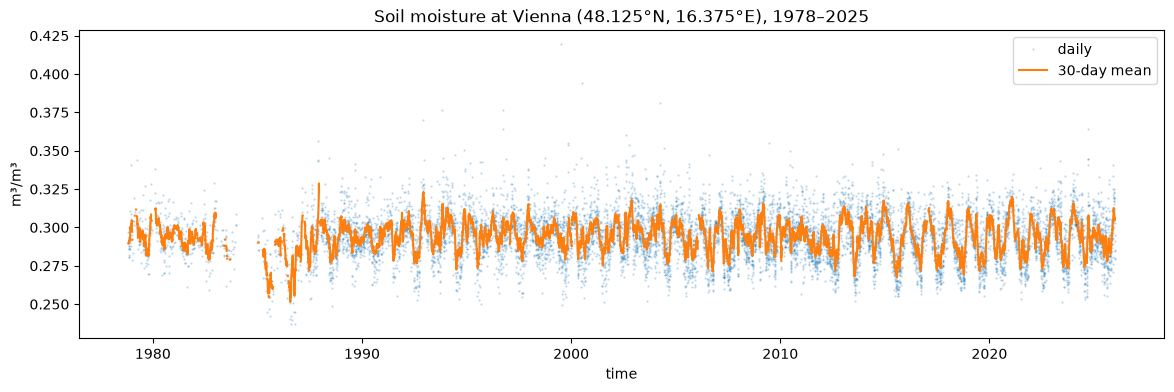

In [26]:
vienna_30d = vienna.rolling(time=30, center=True, min_periods=5).mean()

fig, ax = plt.subplots(figsize=(14, 4))
vienna.plot.line(ax=ax, lw=0, marker=".", ms=1, alpha=0.3, label="daily")
vienna_30d.plot(ax=ax, lw=1.5, color="tab:orange", label="30-day mean")
ax.set_ylabel("m³/m³")
ax.set_title(f"Soil moisture at Vienna ({float(vienna.lat):.3f}°N, {float(vienna.lon):.3f}°E), 1978–2025")
ax.legend()
plt.show()

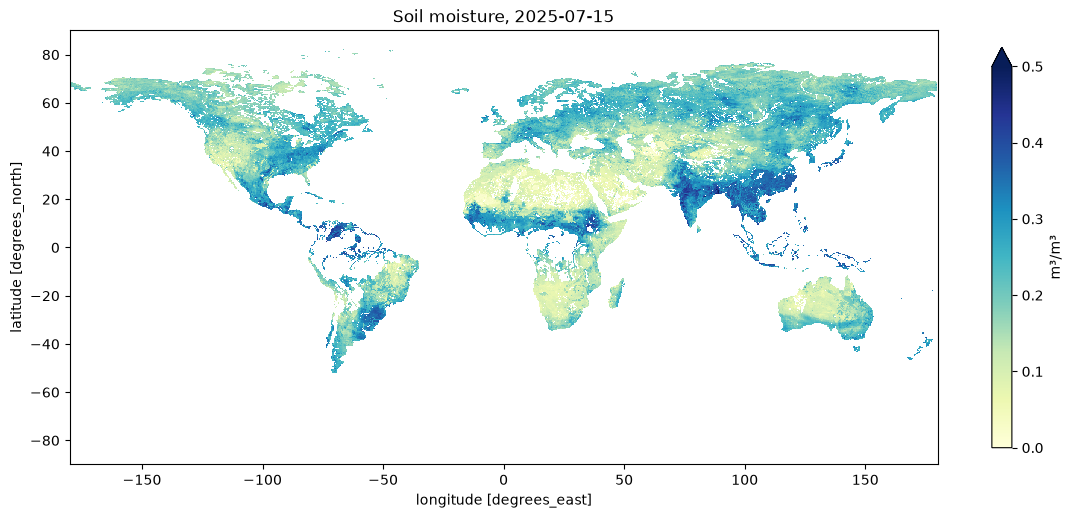

In [27]:
fig, ax = plt.subplots(figsize=(14, 6.5))
global_day.plot(ax=ax, cmap="YlGnBu", vmin=0, vmax=0.5, cbar_kwargs={"label": "m³/m³", "shrink": 0.8})
ax.set_title(f"Soil moisture, {MAP_DAY}")
ax.set_aspect("equal")
plt.show()

## 7. Parallel writing and reading: Zarr vs netCDF

Every Zarr chunk is compressed and stored **independently**, so several threads or processes can
compress and write different chunks at the same time. A netCDF4/HDF5 file has one writer, and the
HDF5 library holds a global lock, so even reads through dask are effectively serialised.

To compare fairly we write the **same data with the same codec** to both formats:
- 100 days of global `sm` (about 415 MB in memory)
- zlib level 9 with byte shuffle, in chunks of 5 days × the full globe

We use the highest compression level so that the work is **CPU-bound**, which is where parallelism pays off.

In [28]:
%%time
# 100 days from a single time chunk of the remote store -> 50 chunk downloads
start = int(np.flatnonzero(ds.time.values == np.datetime64(MAP_DAY))[0]) // chunk_shape[0] * chunk_shape[0]
sm = ds.sm.isel(time=slice(start, start + 100)).load()
sm.encoding = {}  # drop the remote encoding; we set our own below
print(f"{sm.time.size} days, {sm.nbytes / 1e6:.0f} MB in memory")

100 days, 415 MB in memory
CPU times: user 2.5 s, sys: 742 ms, total: 3.24 s
Wall time: 2.9 s


In [29]:
NC_PATH = DATA_DIR / "sm_100days.nc"
ZARR_PATH = DATA_DIR / "sm_100days.zarr"
CHUNKS = {"time": 5, "lat": 720, "lon": 1440}

nc_encoding = {"sm": {"zlib": True, "complevel": 9, "shuffle": True, "chunksizes": tuple(CHUNKS.values())}}
zarr_encoding = {"sm": {"compressors": [zarr.codecs.BloscCodec(cname="zlib", clevel=9, shuffle="shuffle")]}}
timings = {}

t = time.perf_counter()
sm.to_dataset().to_netcdf(NC_PATH, encoding=nc_encoding)
timings["netCDF write"] = time.perf_counter() - t

for n in [1, N_WORKERS]:
    shutil.rmtree(ZARR_PATH, ignore_errors=True)
    with dask.config.set(num_workers=n):
        t = time.perf_counter()
        sm.chunk(CHUNKS).to_dataset().to_zarr(ZARR_PATH, encoding=zarr_encoding, consolidated=False)
        timings[f"Zarr write, {n} thread" + ("s" if n > 1 else "")] = time.perf_counter() - t

for name, seconds in timings.items():
    print(f"{name:25s} {seconds:6.1f} s")

netCDF write                29.5 s
Zarr write, 1 thread        33.6 s
Zarr write, 8 threads        7.0 s


In [18]:
def du(path):
    path = Path(path)
    return path.stat().st_size if path.is_file() else sum(f.stat().st_size for f in path.rglob("*") if f.is_file())


n_files = sum(1 for f in ZARR_PATH.rglob("*") if f.is_file())
print(f"netCDF : {du(NC_PATH) / 1e6:6.1f} MB (1 file)")
print(f"Zarr   : {du(ZARR_PATH) / 1e6:6.1f} MB ({n_files} files)")

netCDF :   62.9 MB (1 file)
Zarr   :   62.8 MB (41 files)


Same codec, so the files are about the same size. With one thread Zarr is about as fast as netCDF, so the
speed-up comes from compressing chunks in parallel, not from a better codec.

Now reading back: compute the mean of the whole array with dask, using 8 threads for both formats.

In [19]:
t = time.perf_counter()
mean_nc = xr.open_dataset(NC_PATH, chunks=CHUNKS).sm.mean().compute()
timings["netCDF read"] = time.perf_counter() - t

t = time.perf_counter()
mean_zarr = xr.open_zarr(ZARR_PATH, consolidated=False).sm.mean().compute()
timings[f"Zarr read, {N_WORKERS} threads"] = time.perf_counter() - t

print("same result:", bool(mean_nc == mean_zarr))
for name in ["netCDF read", f"Zarr read, {N_WORKERS} threads"]:
    print(f"{name:25s} {timings[name]:6.1f} s")

same result: True
netCDF read                  2.3 s
Zarr read, 8 threads         0.7 s


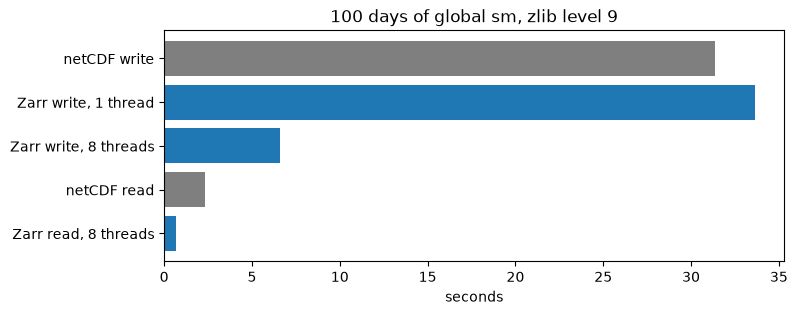

In [20]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(list(timings), list(timings.values()), color=["tab:gray" if "netCDF" in k else "tab:blue" for k in timings])
ax.invert_yaxis()
ax.set_xlabel("seconds")
ax.set_title("100 days of global sm, zlib level 9")
plt.show()

Timings depend on your machine and disk, but the pattern holds: **Zarr scales with cores, netCDF does not**.
The same independence of chunks lets many processes, or many machines, write one store:

```python
# append new days: only new chunks are written
new_days.to_zarr("store.zarr", append_dim="time")

# each worker writes its own region, e.g. one time block, as long as it covers whole chunks
part.to_zarr("store.zarr", region={"time": slice(0, 200)})
```

## 8. Choosing chunks

For the remote store, the work of a request is set by **how many chunks it touches**, not by how many values you want:

In [21]:
def n_chunks(sel):
    # number of chunks touched: product over dims of the distinct chunk indices hit
    n = 1
    for dim, size in zip(("time", "lat", "lon"), chunk_shape):
        idx = np.flatnonzero(ds[dim].isin(np.atleast_1d(sel[dim].values)))
        n *= np.unique(idx // size).size
    return n


cases = {
    "Vienna, 1978–2025": {"time": vienna.time, "lat": vienna.lat, "lon": vienna.lon},
    f"Global, {MAP_DAY}": {"time": global_day.time, "lat": global_day.lat, "lon": global_day.lon},
}
for name, sel in cases.items():
    n = n_chunks(sel)
    wanted = math.prod(np.atleast_1d(v).size for v in sel.values())
    print(f"{name:20s}: {n:3d} chunks touched = {n * math.prod(chunk_shape):>13,d} values read for {wanted:>9,d} wanted")

Vienna, 1978–2025   :  87 chunks touched =   360,806,400 values read for    17,228 wanted
Global, 2025-07-15  :  50 chunks touched =   207,360,000 values read for 1,036,800 wanted


Rules of thumb:
- Aim for chunks of roughly **1–100 MB** (uncompressed).
- Chunk along the dimension you usually slice: small `time` chunks for maps, large `time` chunks for time series.
- Every chunk is a separate file or object, so millions of tiny chunks will be slow.
- If you need both access patterns often, keep **two copies** with different chunking. Storage is usually cheaper than time.

## 9. Cheat sheet: netCDF → Zarr

| Task | netCDF | Zarr |
|---|---|---|
| Open | `xr.open_dataset("f.nc")` | `xr.open_zarr("s.zarr")` or `xr.open_zarr("https://.../s.zarr")` |
| Open lazily with dask | `xr.open_dataset("f.nc", chunks={})` | lazy by default |
| Many files | `xr.open_mfdataset("*.nc")` | usually a single store; append along `time` |
| Header / metadata | `ncdump -h f.nc` | `zarr.open_group(...)`, `arr.info`, or read `zarr.json` |
| Write | `ds.to_netcdf("f.nc")` | `ds.to_zarr("s.zarr")` |
| Append | rewrite the file or add a new file | `ds.to_zarr(..., append_dim="time")` |
| Parallel write | needs MPI-IO | dask / multiple processes, one region each |
| Compression | `encoding={"v": {"zlib": True}}` | `encoding={"v": {"compressors": [...]}}` |
| Chunking | `encoding={"v": {"chunksizes": ...}}` | `ds.chunk(...)` before writing, or `encoding={"v": {"chunks": ...}}` |

## Summary

- From xarray, Zarr feels almost the same as netCDF. The main difference is in the storage layout.
- The whole C3S record is one store: one URL, one metadata request, and only the chunks you need are downloaded.
- Chunks are independent, so reading and writing scale with the number of cores.
- Choosing chunks that match how you access the data is the most important performance decision.